# CS 5785 midterm · Trial outcome prediction

## Summary
The frozen baseline was phase-specific TF-IDF logistic regression with C=3. On official validation, the selected challenger reduced mean phase log loss from **0.5692 to 0.5519**. On the 2010–2013 holdout, its log loss rose from the baseline's **0.5788 to 0.5844**. The train-only CSV uses the selected challenger. Pri's exact Kaggle model is still needed for an incumbent comparison.

## Context and methods

Predict the probability that a trial meets its primary endpoint. The official validation split measures performance on trials from the same period as training. The temporal split uses training trials before 2010 for fitting and trials from 2010–2013 for evaluation. Kaggle gives each phase equal weight in log loss. For the assignment, F1 uses a probability cutoff of 0.5, and PR-AUC is average precision.

Open this notebook from the repository root or the **Part 2** directory. The required packages are NumPy, pandas, SciPy, scikit-learn (1.4 or later), and Matplotlib. The inputs are the course-supplied CSVs alongside this notebook and the committed Part 1 reason labels. Pri's exact submitted model is pending. The improved model here is a separate challenger.

In [1]:
import ast
import re
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csr_matrix, hstack
from sklearn.calibration import calibration_curve
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.naive_bayes import MultinomialNB

DATA = Path.cwd()
if not (DATA / "outcome_train.csv").is_file():
    DATA = DATA / "Part 2"

PHASES = ("I", "II", "III")
FIELDS = ("criteria", "diseases_cleaned", "icdcodes", "drugs")
REASONS = ("Safety", "Funding", "Efficacy", "Recruitment", "Other")
HANDOFF_COLUMNS = ["ID", "trial_id", "phase", "label"]
SEED = 5785
CLOSE_LOSS = 0.002
EPSILON = 1e-6
THRESHOLD = 0.5

## Data

Keep one row per trial-phase pair. A combined-phase trial can have two rows, so both rows must go into the same cross-validation fold. The modeling inputs are built explicitly from the supplied trial fields. IDs identify rows and groups. The Part 1 label join appears only after the baseline has produced validation predictions.

In [2]:
train = pd.read_csv(DATA / "outcome_train.csv")
val = pd.read_csv(DATA / "outcome_val.csv")
test = pd.read_csv(DATA / "outcome_test.csv")
sample = pd.read_csv(DATA / "part2_sample_submission.csv")

for frame in (train, val, test):
    assert frame["ID"].is_unique
    assert set(frame["phase"]) == set(PHASES)

for left, right in ((train, val), (train, test), (val, test)):
    assert set(left["trial_id"]).isdisjoint(right["trial_id"])

assert train.groupby("trial_id")["label"].nunique().max() == 1
assert train.groupby("trial_id")["start_year"].nunique(dropna=False).max() == 1
assert (len(train), len(val), len(test)) == (8037, 1013, 1500)
assert test["phase"].value_counts().eq(500).all()
assert test["start_year"].min() > train["start_year"].max()
assert test["start_year"].min() > val["start_year"].max()
assert list(sample.columns) == ["ID", "label"]
assert sample["ID"].equals(test["ID"])

early = train.loc[train["start_year"] < 2010].reset_index(drop=True)
late = train.loc[train["start_year"].between(2010, 2013)].reset_index(drop=True)
assert set(early["trial_id"]).isdisjoint(late["trial_id"])

for name, frame in (("Train", train), ("Validation", val), ("Temporal holdout", late)):
    by_phase = frame.groupby("phase")["label"].agg(rows="size", success_rate="mean")
    print(name)
    display(by_phase.round(3))
print(f"Excluded from the temporal split due to missing year: {train['start_year'].isna().sum()}")

Train
Validation
Temporal holdout
Excluded from the temporal split due to missing year: 21


,rows,success_rate
phase,,
I,1012,0.566
II,3950,0.477
III,3075,0.653


,rows,success_rate
phase,,
I,149,0.570
II,501,0.471
III,363,0.661


,rows,success_rate
phase,,
I,326,0.626
II,958,0.569
III,731,0.769


### How much does the test data shift?

The vocabulary check counts unseen token **occurrences**, using lowercase word tokens of at least two characters and a vocabulary from training. These are descriptive checks on the supplied text and years. Model fitting and selection use the labeled splits.

,Validation unseen (%),Test unseen (%)
Field,,
criteria,0.41,0.84
diseases_cleaned,1.84,5.18
icdcodes,0.35,1.27
drugs,9.23,24.19


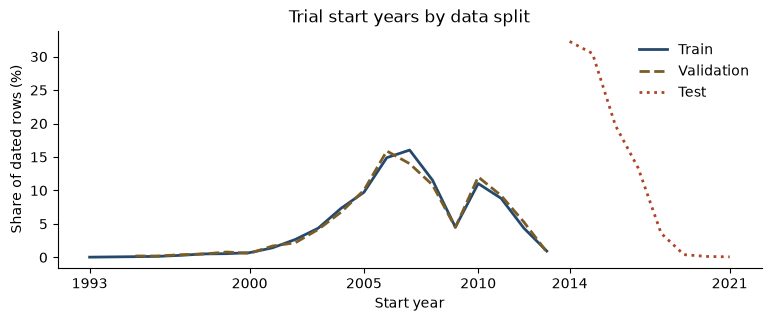

In [3]:
tokenize = CountVectorizer().build_analyzer()
shift_rows = []
for field in FIELDS:
    vocabulary = set()
    for text in train[field].fillna(""):
        vocabulary.update(tokenize(text))
    row = {"Field": field}
    for name, frame in (("Validation", val), ("Test", test)):
        tokens = [word for text in frame[field].fillna("") for word in tokenize(text)]
        row[name] = 100 * sum(word not in vocabulary for word in tokens) / len(tokens)
    shift_rows.append(row)

shift_table = pd.DataFrame(shift_rows).set_index("Field")
display(shift_table.round(2).rename(columns=lambda split: f"{split} unseen (%)"))

fig, ax = plt.subplots(figsize=(7.6, 3.1), layout="constrained")
for frame, name, color, style in (
    (train, "Train", "#25496d", "-"),
    (val, "Validation", "#7a5c26", "--"),
    (test, "Test", "#ad4428", ":"),
):
    shares = frame["start_year"].dropna().astype(int).value_counts(normalize=True).sort_index()
    ax.plot(shares.index, 100 * shares, label=name, color=color, linestyle=style, linewidth=2)
ax.set(title="Trial start years by data split", xlabel="Start year", ylabel="Share of dated rows (%)")
ax.set_xticks([1993, 2000, 2005, 2010, 2014, 2021])
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Feature and model setup

The baseline compares phase rates, multinomial Naive Bayes on counts, and logistic regression on TF-IDF. We compare separate phase classifiers with a pooled classifier that receives phase indicators. We fit each vocabulary on the rows used to train that fold. Separate phase classifiers share the vocabulary learned from the fold's training rows.

The improved model candidates add trial design summaries, phase-specific text coefficients with shared coefficients, recency weighting, or the supplied drug-knowledge fields. All features are available in the outcome data. A four-year recency half-life gives a trial four years older than the newest training year half the weight before normalizing the weights to mean one.

In [4]:
@dataclass(frozen=True)
class Model:
    name: str
    family: str
    scope: str = "phase"
    text: str = "tfidf"
    strength: float = 1
    design: bool = False
    half_life: int = 0
    drug_knowledge: bool = False


phase_rate = Model("Phase rate", "rate")
baseline_models = [phase_rate]
for scope in ("phase", "pooled"):
    for alpha in (0.25, 1.0):
        baseline_models.append(Model(f"NB {scope} alpha={alpha:g}", "nb", scope, "count", alpha))
    for strength in (0.5, 3, 12):
        baseline_models.append(Model(f"LR {scope} C={strength:g}", "lr", scope, "tfidf", strength))
baseline_models.extend([
    Model("LR phase unigrams C=3", "lr", text="unigrams", strength=3),
    Model("LR phase separate fields C=3", "lr", text="fields", strength=3),
])

challenger_groups = {
    "Trial design": [
        Model(f"LR phase design C={c:g}", "lr", strength=c, design=True) for c in (0.5, 3, 12)
    ],
    "Shared coefficients": [
        Model(f"LR shared design C={c:g}", "lr", scope="shared", strength=c, design=True)
        for c in (0.5, 3, 12)
    ],
    "Recency weighting": [
        Model(f"LR shared design {years}y C=3", "lr", scope="shared", strength=3, design=True,
              half_life=years)
        for years in (4, 8)
    ],
    "Drug knowledge": [
        Model("LR shared design drug knowledge C=3", "lr", scope="shared", strength=3,
              design=True, drug_knowledge=True)
    ],
}

In [5]:
def item_count(value):
    # Count entries in a serialized list, including nested ICD lists.
    if not isinstance(value, str) or not value.strip():
        return 0
    if not value.startswith("["):
        return 1
    try:
        items = ast.literal_eval(value)
    except (SyntaxError, ValueError):
        return 1
    if isinstance(items, list):
        return sum(item_count(item) for item in items)
    return 1


def design_features(frame):
    records = []
    for row in frame.itertuples(index=False):
        criteria = row.criteria
        records.append({
            "criteria length": np.log1p(len(criteria.split())) / 4,
            "bullet count": np.log1p(len(re.findall(r"(?m)^\s*[-*]", criteria))) / 2,
            "has exclusion heading": float("exclusion criteria" in criteria.lower()),
            "mentions placebo": float("placebo" in (criteria + " " + row.drugs).lower()),
            "drug count": np.log1p(item_count(row.drugs)),
            "disease count": np.log1p(item_count(row.diseases_cleaned)),
            "ICD count": np.log1p(item_count(row.icdcodes)),
            "phase detail": row.phase_detail,
        })
    return records


def knowledge_text(frame):
    fields = ("matched_drugs", "drug_targets", "drug_actions", "drug_pathways")
    records = []
    for row in frame[list(fields)].fillna("").itertuples(index=False, name=None):
        tokens = []
        for field, entries in zip(fields, row):
            for entry in entries.lower().split(";"):
                entry = entry.strip()
                if entry:
                    tokens.append(field + "_" + re.sub(r"\W+", "_", entry))
        records.append(" ".join(tokens))
    return records


def prepare_rows(frame):
    prepared = frame.copy()
    for field in FIELDS:
        prepared[field] = prepared[field].fillna("")
    prepared["phase_detail"] = prepared["phase_detail"].fillna("unknown")
    # Preserve the dot-delimited ICD code as one token in the text models.
    prepared["icdcodes"] = prepared["icdcodes"].str.replace(".", "_", regex=False)
    prepared["text"] = prepared[list(FIELDS)].agg(" ".join, axis=1)
    prepared["design"] = design_features(prepared)
    prepared["knowledge"] = knowledge_text(prepared)
    return prepared


train, val, test, early, late = [prepare_rows(frame) for frame in (train, val, test, early, late)]

In [6]:
def vectorize(fit, evaluation, representation):
    if representation == "count":
        vectorizer = CountVectorizer(min_df=3, max_features=40_000)
        return vectorizer.fit_transform(fit["text"]), vectorizer.transform(evaluation["text"])

    fields = FIELDS if representation == "fields" else ("text",)
    fit_blocks, evaluation_blocks = [], []
    for field in fields:
        max_features = 40_000 if field in ("text", "criteria") else 5_000
        ngrams = (1, 1) if representation == "unigrams" else (1, 2)
        vectorizer = TfidfVectorizer(
            min_df=3, max_features=max_features, ngram_range=ngrams, sublinear_tf=True
        )
        fit_blocks.append(vectorizer.fit_transform(fit[field]))
        evaluation_blocks.append(vectorizer.transform(evaluation[field]))
    return hstack(fit_blocks, format="csr"), hstack(evaluation_blocks, format="csr")


def add_phase(matrix, frame, scope):
    if scope == "phase":
        return matrix
    phase_columns = [frame["phase"].eq(phase).to_numpy(dtype=float) for phase in PHASES]
    blocks = [matrix, csr_matrix(np.column_stack(phase_columns))]
    if scope == "shared":
        for phase_column in phase_columns:
            blocks.append(matrix.multiply(phase_column[:, None]))
    return hstack(blocks, format="csr")


def estimate(model):
    if model.family == "nb":
        return MultinomialNB(alpha=model.strength)
    return LogisticRegression(C=model.strength, solver="liblinear", random_state=SEED)


def fit_predict(fit, evaluation, models):
    y = fit["label"].to_numpy()
    predictions = {}
    text_cache = {}
    matrix_cache = {}
    design_pair = knowledge_pair = None
    for model in models:
        if model.family == "rate":
            rates = fit.groupby("phase")["label"].mean()
            predictions[model.name] = evaluation["phase"].map(rates).to_numpy()
            continue

        if model.text not in text_cache:
            text_cache[model.text] = vectorize(fit, evaluation, model.text)
        key = (model.text, model.design, model.drug_knowledge, model.scope)
        if key not in matrix_cache:
            fit_text, evaluation_text = text_cache[model.text]
            fit_blocks, evaluation_blocks = [fit_text], [evaluation_text]
            if model.design:
                if design_pair is None:
                    design = DictVectorizer()
                    design_pair = design.fit_transform(fit["design"]), design.transform(evaluation["design"])
                fit_blocks.append(design_pair[0])
                evaluation_blocks.append(design_pair[1])
            if model.drug_knowledge:
                if knowledge_pair is None:
                    knowledge = TfidfVectorizer(min_df=4, max_features=2500)
                    knowledge_pair = (
                        knowledge.fit_transform(fit["knowledge"]),
                        knowledge.transform(evaluation["knowledge"]),
                    )
                fit_blocks.append(knowledge_pair[0])
                evaluation_blocks.append(knowledge_pair[1])

            fit_matrix = add_phase(hstack(fit_blocks, format="csr"), fit, model.scope)
            evaluation_matrix = add_phase(hstack(evaluation_blocks, format="csr"), evaluation, model.scope)
            matrix_cache[key] = fit_matrix, evaluation_matrix

        fit_matrix, evaluation_matrix = matrix_cache[key]
        weights = np.ones(len(fit))
        if model.half_life:
            year = fit["start_year"].fillna(fit["start_year"].median())
            weights = np.power(0.5, (year.max() - year.to_numpy()) / model.half_life)
            weights /= weights.mean()

        if model.scope == "phase":
            probability = np.empty(len(evaluation))
            for phase in PHASES:
                fit_mask = fit["phase"].eq(phase).to_numpy()
                evaluation_mask = evaluation["phase"].eq(phase).to_numpy()
                classifier = estimate(model)
                classifier.fit(fit_matrix[fit_mask], y[fit_mask], sample_weight=weights[fit_mask])
                probability[evaluation_mask] = classifier.predict_proba(
                    evaluation_matrix[evaluation_mask]
                )[:, 1]
        else:
            classifier = estimate(model)
            classifier.fit(fit_matrix, y, sample_weight=weights)
            probability = classifier.predict_proba(evaluation_matrix)[:, 1]

        predictions[model.name] = np.clip(probability, EPSILON, 1 - EPSILON)
    return predictions

### Grouped training folds and metrics

In each fold, we predict held-out trials from an estimator trained on the other folds. These out-of-fold predictions select baseline settings and later fit calibration maps. The official validation set stays outside both processes. The temporal check uses the same procedure within the earlier training cohort.

In [7]:
def out_of_fold(frame, models):
    splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
    strata = frame["phase"] + "-" + frame["label"].astype(str)
    probabilities = {model.name: np.full(len(frame), np.nan) for model in models}
    seen = np.zeros(len(frame), dtype=int)
    for fit_idx, holdout_idx in splitter.split(frame, strata, groups=frame["trial_id"]):
        fit = frame.iloc[fit_idx]
        holdout = frame.iloc[holdout_idx]
        assert set(fit["trial_id"]).isdisjoint(holdout["trial_id"])
        assert all(holdout.groupby("phase")["label"].nunique().reindex(PHASES).eq(2))
        seen[holdout_idx] += 1
        for name, prediction in fit_predict(fit, holdout, models).items():
            probabilities[name][holdout_idx] = prediction
    assert np.all(seen == 1)
    assert all(np.isfinite(probability).all() for probability in probabilities.values())
    return probabilities


def mean_loss(frame, probability):
    losses = []
    for phase in PHASES:
        mask = frame["phase"].eq(phase).to_numpy()
        losses.append(log_loss(frame.loc[mask, "label"], probability[mask], labels=[0, 1]))
    return float(np.mean(losses))


def metric_table(frame, probability):
    rows = []
    for phase in PHASES:
        mask = frame["phase"].eq(phase).to_numpy()
        actual = frame.loc[mask, "label"]
        predicted = probability[mask]
        rows.append({
            "Phase": phase,
            "n": mask.sum(),
            "F1": f1_score(actual, predicted >= THRESHOLD),
            "ROC-AUC": roc_auc_score(actual, predicted),
            "AP": average_precision_score(actual, predicted),
            "Log loss": log_loss(actual, predicted, labels=[0, 1]),
        })
    result = pd.DataFrame(rows).set_index("Phase")
    result.loc["Phase mean"] = result.mean()
    result.loc["Phase mean", "n"] = len(frame)
    result["n"] = result["n"].astype(int)
    return result


def training_scores(frame, predictions):
    return pd.Series({
        name: mean_loss(frame, probability) for name, probability in predictions.items()
    }, name="Grouped train log loss").sort_values()

## Results

### Freeze the baseline

The baseline is the best uncalibrated configuration by grouped training log loss. The validation CSV is the handoff for Pri. The phase-rate row provides a reference for interpreting both validation splits.

In [8]:
baseline_oof = out_of_fold(train, baseline_models)
baseline_cv = training_scores(train, baseline_oof)
display(baseline_cv.round(4).to_frame())

baseline = next(model for model in baseline_models if model.name == baseline_cv.idxmin())
baseline_val = fit_predict(train, val, [baseline])[baseline.name]
baseline_late = fit_predict(early, late, [baseline])[baseline.name]
print(f"Frozen baseline: {baseline.name}")
display(metric_table(val, baseline_val).round(4))

baseline_handoff = val[HANDOFF_COLUMNS].copy()
baseline_handoff["prob"] = baseline_val
baseline_handoff["pred"] = (baseline_val >= THRESHOLD).astype(int)
baseline_handoff.to_csv(DATA / "baseline_val_preds.csv", index=False)

Frozen baseline: LR phase C=3


,Grouped train log loss
LR phase C=3,0.5904
LR pooled C=3,0.5925
LR phase unigrams C=3,0.5997
LR pooled C=0.5,0.6010
LR phase C=12,0.6089
LR phase C=0.5,0.6120
LR phase separate fields C=3,0.6293
LR pooled C=12,0.6314
Phase rate,0.6739
NB phase alpha=1,3.6491


,n,F1,ROC-AUC,AP,Log loss
Phase,,,,,
I,149,0.7892,0.7851,0.8166,0.5723
II,501,0.6250,0.7224,0.7125,0.6076
III,363,0.8229,0.7756,0.8741,0.5276
Phase mean,1013,0.7457,0.7610,0.8011,0.5692


### Error analysis uses the team's Part 1 labels

For each failed validation trial-phase pair, count false positives among the applicable reasons. A row with multiple reasons contributes to each group. The no-recorded-reason group contains failed rows without a Part 1 match. Empty groups have a missing rate. Small groups and predicted reason labels make differences uncertain.

In [9]:
reason_labels = pd.read_csv(DATA.parent / "Part 1" / "reason_labels.csv")
assert reason_labels["ID"].is_unique
assert set(reason_labels["source"]) == {"true", "predicted"}
reason_lookup = reason_labels[["ID", *REASONS, "source"]].rename(columns={"ID": "trial_id"})


def reason_errors(predictions):
    failed = predictions.loc[predictions["label"].eq(0)].merge(
        reason_lookup, on="trial_id", how="left", validate="many_to_one"
    )
    rows = []
    for phase in PHASES:
        in_phase = failed.loc[failed["phase"].eq(phase)]
        for reason in (*REASONS, "No recorded reason"):
            if reason == "No recorded reason":
                group = in_phase.loc[in_phase["source"].isna()]
            else:
                group = in_phase.loc[in_phase[reason].eq(1)]
            rows.append({
                "phase": phase, "reason": reason, "n": len(group),
                "n_true": group["source"].eq("true").sum(),
                "n_predicted": group["source"].eq("predicted").sum(),
                "n_no_recorded": group["source"].isna().sum(),
                "baseline_fp": int(group["pred"].sum()),
                "baseline_fpr": group["pred"].mean(),
                "challenger_fp": int(group["challenger_pred"].sum()),
                "challenger_fpr": group["challenger_pred"].mean(),
            })
    return pd.DataFrame(rows)


baseline_error_table = reason_errors(baseline_handoff.assign(challenger_pred=baseline_handoff["pred"]))
display(baseline_error_table[["phase", "reason", "n", "baseline_fpr"]].round(3))

,phase,reason,n,baseline_fpr
0,I,Safety,8,0.375
1,I,Funding,4,0.500
2,I,Efficacy,2,1.000
3,I,Recruitment,23,0.304
4,I,Other,4,0.500
5,I,No recorded reason,28,0.500
6,II,Safety,13,0.462
7,II,Funding,4,0.500
8,II,Efficacy,10,0.300
9,II,Recruitment,89,0.202


### Improve and calibrate the model

The reason table suggests two questions. Can criteria structure and trial design explain some recruitment-related errors? Can smaller phases benefit from shared text coefficients? The alternatives also test drug knowledge and whether giving later training trials more weight improves generalization.

Keep the best setting within each alternative according to grouped training log loss. Fit sigmoid and isotonic maps separately for each phase from out-of-fold predictions. Both maps see only the corresponding training cohort. A calibrated variant qualifies if it beats raw probabilities on official validation and at least ties them on the temporal check. Among candidates within 0.002 of the best official validation log loss, prefer the one with lower temporal log loss. Pri's incumbent and a blend with it require his exact code.

In [10]:
challenger_models = []
for group_models in challenger_groups.values():
    challenger_models.extend(group_models)

challenger_oof = out_of_fold(train, challenger_models)
challenger_cv = training_scores(train, challenger_oof)
shortlist = [baseline]
for group, group_models in challenger_groups.items():
    best = min(group_models, key=lambda model: challenger_cv.loc[model.name])
    shortlist.append(best)
    print(f"{group}: {best.name} ({challenger_cv.loc[best.name]:.4f} grouped log loss)")

all_oof = {**baseline_oof, **challenger_oof}
early_oof = out_of_fold(early, shortlist)
validation_raw = fit_predict(train, val, shortlist)
temporal_raw = fit_predict(early, late, shortlist)

# The phase-rate baseline is a useful comparator when phase prevalence changes.
rate_val = fit_predict(train, val, [phase_rate])[phase_rate.name]
rate_late = fit_predict(early, late, [phase_rate])[phase_rate.name]

Trial design: LR phase design C=3 (0.5920 grouped log loss)
Shared coefficients: LR shared design C=0.5 (0.5925 grouped log loss)
Recency weighting: LR shared design 8y C=3 (0.5944 grouped log loss)
Drug knowledge: LR shared design drug knowledge C=3 (0.6050 grouped log loss)


In [11]:
def log_odds(probability):
    safe = np.clip(probability, EPSILON, 1 - EPSILON)
    return np.log(safe / (1 - safe)).reshape(-1, 1)


def calibrate(method, fit, oof, evaluation, raw):
    if method == "raw":
        return raw
    probability = np.empty(len(evaluation))
    for phase in PHASES:
        fit_mask = fit["phase"].eq(phase).to_numpy()
        evaluation_mask = evaluation["phase"].eq(phase).to_numpy()
        actual = fit.loc[fit_mask, "label"]
        if method == "sigmoid":
            mapper = LogisticRegression(C=1000, solver="lbfgs")
            mapper.fit(log_odds(oof[fit_mask]), actual)
            probability[evaluation_mask] = mapper.predict_proba(
                log_odds(raw[evaluation_mask])
            )[:, 1]
        else:
            mapper = IsotonicRegression(out_of_bounds="clip")
            mapper.fit(oof[fit_mask], actual)
            probability[evaluation_mask] = mapper.predict(raw[evaluation_mask])
    return np.clip(probability, EPSILON, 1 - EPSILON)


methods = ("raw", "sigmoid", "isotonic")
validation_predictions = {}
temporal_predictions = {}
comparison = []
for model in shortlist:
    name = model.name
    for method in methods:
        key = (name, method)
        validation_predictions[key] = calibrate(
            method, train, all_oof[name], val, validation_raw[name]
        )
        temporal_predictions[key] = calibrate(
            method, early, early_oof[name], late, temporal_raw[name]
        )
        comparison.append({
            "model": name, "calibration": method,
            "validation": mean_loss(val, validation_predictions[key]),
            "temporal": mean_loss(late, temporal_predictions[key]),
        })

scores = pd.DataFrame(comparison).set_index(["model", "calibration"])
scores["eligible"] = False
for model in shortlist:
    raw_score = scores.loc[(model.name, "raw")]
    for method in methods:
        score = scores.loc[(model.name, method)]
        scores.loc[(model.name, method), "eligible"] = method == "raw" or (
            score["validation"] < raw_score["validation"] and score["temporal"] <= raw_score["temporal"]
        )
display(scores.round(4))

# Choose the best improvement candidate even if the baseline ultimately remains the submission.
alternatives = scores.loc[scores["eligible"]].drop(index=baseline.name, level="model")
competitive = alternatives.loc[alternatives["validation"] <= alternatives["validation"].min() + CLOSE_LOSS]
challenger_key = competitive.sort_values(["temporal", "validation"]).index[0]
challenger = next(model for model in shortlist if model.name == challenger_key[0])
challenger_val = validation_predictions[challenger_key]
challenger_late = temporal_predictions[challenger_key]

eligible = scores.loc[scores["eligible"]]
competitive = eligible.loc[eligible["validation"] <= eligible["validation"].min() + CLOSE_LOSS]
submission_key = competitive.sort_values(["temporal", "validation"]).index[0]
submission_model = next(model for model in shortlist if model.name == submission_key[0])

print(f"Improved candidate: {challenger_key}")
print(f"Selected for train-only export: {submission_key}")

Improved candidate: ('LR shared design 8y C=3', 'raw')
Selected for train-only export: ('LR shared design 8y C=3', 'raw')


validation  temporal  eligible
model                               calibration                                
LR phase C=3                        raw              0.5692    0.5788      True
                                    sigmoid          0.5660    0.5820     False
                                    isotonic         0.5602    0.6019     False
LR phase design C=3                 raw              0.5656    0.5817      True
                                    sigmoid          0.5653    0.5840     False
                                    isotonic         0.5618    0.6077     False
LR shared design C=0.5              raw              0.5650    0.5758      True
                                    sigmoid          0.5601    0.5732      True
                                    isotonic         0.5596    0.5913     False
LR shared design 8y C=3             raw              0.5519    0.5844      True
                                    sigmoid          0.5521    0.5804     False
                                    isotonic         0.5515    0.6008     False
LR shared design drug knowledge C=3 raw              0.5642    0.5990      True
                                    sigmoid          0.5609    0.5867      True
                                    isotonic         0.5654    0.6394     False

### Compare models and check the predicted probabilities

The tables show per-phase results and equal-phase means on both splits. Reliability plots compare the observed success fraction with the mean predicted probability in each validation bin. The bins contain approximately equal numbers of rows. The diagonal represents perfect agreement.

Official validation
Temporal holdout


Phase rate                  ... Challenger                 
                   F1 ROC-AUC      AP  ...    ROC-AUC      AP Log loss
Phase                                  ...                            
I              0.7265     0.5  0.5705  ...     0.8037  0.8404   0.5373
II             0.0000     0.5  0.4711  ...     0.7352  0.7254   0.6104
III            0.7960     0.5  0.6612  ...     0.7918  0.8778   0.5080
Phase mean     0.5075     0.5  0.5676  ...     0.7769  0.8146   0.5519

[4 rows x 13 columns]

Phase rate                  ... Challenger                 
                   F1 ROC-AUC      AP  ...    ROC-AUC      AP Log loss
Phase                                  ...                            
I              0.7698     0.5  0.6258  ...     0.6081  0.6859   0.6640
II             0.0000     0.5  0.5689  ...     0.7223  0.7625   0.6093
III            0.8693     0.5  0.7688  ...     0.7319  0.8854   0.4800
Phase mean     0.5464     0.5  0.6545  ...     0.6874  0.7779   0.5844

[4 rows x 13 columns]

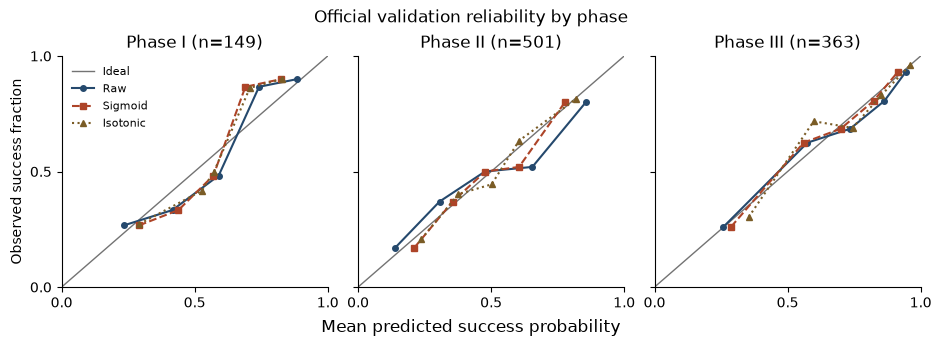

In [12]:
for split_name, frame, rate, original, improved in (
    ("Official validation", val, rate_val, baseline_val, challenger_val),
    ("Temporal holdout", late, rate_late, baseline_late, challenger_late),
):
    print(split_name)
    display(pd.concat({
        "Phase rate": metric_table(frame, rate).drop(columns="n"),
        "Baseline": metric_table(frame, original),
        "Challenger": metric_table(frame, improved).drop(columns="n"),
    }, axis=1).round(4))

fig, axes = plt.subplots(1, 3, figsize=(9.3, 3.35), sharex=True, sharey=True, layout="constrained")
styles = {
    "raw": ("#25496d", "o", "-"),
    "sigmoid": ("#ad4428", "s", "--"),
    "isotonic": ("#7a5c26", "^", ":"),
}
for phase, ax in zip(PHASES, axes):
    mask = val["phase"].eq(phase).to_numpy()
    ax.plot([0, 1], [0, 1], color="#737373", linewidth=1, label="Ideal")
    for method in methods:
        probability = validation_predictions[(challenger.name, method)][mask]
        observed, predicted = calibration_curve(val.loc[mask, "label"], probability,
                                               n_bins=5, strategy="quantile")
        color, marker, style = styles[method]
        ax.plot(predicted, observed, color=color, marker=marker, linestyle=style,
                label=method.capitalize(), markersize=4)
    ax.set(title=f"Phase {phase} (n={mask.sum()})", xlim=(0, 1), ylim=(0, 1))
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Observed success fraction")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Official validation reliability by phase")
fig.supxlabel("Mean predicted success probability")
plt.show()

### Before-and-after errors and the submission file

Both error columns use 0.5 and the same failed validation rows. The error-rate change is challenger minus baseline. The submission refits the chosen configuration on the full official training split. Validation and test are separate from that refit.

In [13]:
paired = baseline_handoff.assign(
    challenger_prob=challenger_val,
    challenger_pred=(challenger_val >= THRESHOLD).astype(int),
)
error_table = reason_errors(paired)
error_table["fpr_change"] = error_table["challenger_fpr"] - error_table["baseline_fpr"]
assert (error_table["n_true"] + error_table["n_predicted"] + error_table["n_no_recorded"]).equals(
    error_table["n"]
)
assert error_table.loc[error_table["n"].eq(0), ["baseline_fpr", "challenger_fpr"]].isna().all().all()
assert error_table.loc[error_table["reason"].eq("No recorded reason"), "n"].sum() == 254
paired.to_csv(DATA / "part2_val_comparison.csv", index=False)
error_table.to_csv(DATA / "part2_error_analysis.csv", index=False)
display(error_table.round(3).fillna("N/A"))

test_raw = fit_predict(train, test, [submission_model])[submission_model.name]
test_probability = calibrate(
    submission_key[1], train, all_oof[submission_model.name], test, test_raw
)
submission = sample[["ID"]].copy()
submission["label"] = test_probability
assert submission.shape == (1500, 2)
assert submission["ID"].is_unique and submission["ID"].equals(sample["ID"])
assert np.isfinite(submission["label"]).all() and submission["label"].between(0, 1).all()
submission.to_csv(DATA / "part2_submission_train_only.csv", index=False)
display(submission.head())

,phase,reason,n,n_true,n_predicted,n_no_recorded,baseline_fp,baseline_fpr,challenger_fp,challenger_fpr,fpr_change
0,I,Safety,8,1,7,0,3,0.375,3,0.375,0.0
1,I,Funding,4,1,3,0,2,0.5,2,0.5,0.0
2,I,Efficacy,2,0,2,0,2,1.0,1,0.5,-0.5
3,I,Recruitment,23,2,21,0,7,0.304,6,0.261,-0.043
4,I,Other,4,0,4,0,2,0.5,2,0.5,0.0
5,I,No recorded reason,28,0,0,28,14,0.5,12,0.429,-0.071
6,II,Safety,13,1,12,0,6,0.462,6,0.462,0.0
7,II,Funding,4,1,3,0,2,0.5,2,0.5,0.0
8,II,Efficacy,10,0,10,0,3,0.3,3,0.3,0.0
9,II,Recruitment,89,12,77,0,18,0.202,20,0.225,0.022


,ID,label
0,TR11252_III,0.733597
1,TR08672_II,0.624238
2,TR07815_I,0.749138
3,TR08013_I,0.632178
4,TR05100_II,0.523846


## Takeaways
- The selected challenger uses shared and phase-specific coefficients, trial-design features, and an eight-year recency half-life. Its raw probabilities won on official validation. The temporal result limits how confidently we can transfer that result to test.
- A different shared model (C=0.5, no recency weighting, sigmoid calibration) improved over the frozen baseline on both official validation (0.5601) and the temporal holdout (0.5732). Include it when comparing with the incumbent. The later training rows informed shortlisting and the temporal check informed selection, so use that split as a sensitivity check.
- Phase III recruitment false positives fell from 11 of 22 to 8 of 22. Only five of these 22 reason labels are true labels, and smaller groups can move by double-digit percentages with one prediction change.

### References and handoff

- Course midterm directions, pp. 5–8, and the course-provided outcome CSVs.
- [Scikit-learn user guide on probability calibration](https://scikit-learn.org/stable/modules/calibration.html).
- The team's Part 1 notebook and its committed reason label export provide the error-analysis categories.
- The shared study reference suggested testing trial design, phase pooling, and recency. The models and evaluation here were implemented and run on the team's files. Codex assisted with implementation, checking, and report drafting.

## Second round · Generalization to newer trials

The original candidate performed better on the official validation set than on the temporal split. This round tests character n-grams for drug names, separate indication features, additional criteria summaries, and a start-year feature capped two years beyond the training range. A histogram gradient boosting classifier on compressed text and trial descriptors provides a different signal. A cosine-neighbor model tests whether similar trials help.

The assignment gives a combined-phase trial the same binary outcome in each phase. We pool those predictions by trial ID using inverse phase sizes, which match the equal-phase log loss. This uses the ID to associate rows for the same trial. The training features exclude IDs and Part 1 data. The comparator uses the probabilities from the previous submission model before pooling.

In [14]:
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics.pairwise import cosine_similarity


def round_two_design(frame):
    records = []
    for row in frame.itertuples(index=False):
        criteria = row.criteria.lower()
        lines = [line.strip() for line in criteria.splitlines() if line.strip()]
        before, _, after = criteria.partition("exclusion criteria")
        records.append({
            **row.design,
            "inclusion words": np.log1p(len(before.split())) / 4,
            "exclusion words": np.log1p(len(after.split())) / 4,
            "nonempty lines": np.log1p(len(lines)) / 3,
            "digits per hundred characters": 100 * sum(c.isdigit() for c in criteria) / max(len(criteria), 1),
            "healthy volunteer": float(bool(re.search(r"\bhealthy (volunteer|subject|adult)", criteria))),
            "prior treatment": float(bool(re.search(r"\b(prior|previous) (treatment|therapy)", criteria))),
            "known drug": float(pd.notna(row.matched_drugs)),
        })
    return records


def phase_interactions(matrix, frame):
    flags = np.column_stack([frame["phase"].eq(phase) for phase in PHASES])
    blocks = [matrix, csr_matrix(flags)]
    for flag in flags.T:
        blocks.append(matrix.multiply(0.65 * flag[:, None]))
    return hstack(blocks, format="csr")


def fit_round_two(fit, evaluation):
    labels = fit["label"].to_numpy()
    words_fit, words_evaluation = vectorize(fit, evaluation, "tfidf")

    drug_chars = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=18_000)
    drug_fit = drug_chars.fit_transform(fit["drugs"])
    drug_evaluation = drug_chars.transform(evaluation["drugs"])

    indication = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=10_000, sublinear_tf=True)
    indication_fit = indication.fit_transform(fit["diseases_cleaned"] + " " + fit["icdcodes"])
    indication_evaluation = indication.transform(evaluation["diseases_cleaned"] + " " + evaluation["icdcodes"])

    design_encoder = DictVectorizer()
    design_fit = design_encoder.fit_transform(round_two_design(fit))
    design_evaluation = design_encoder.transform(round_two_design(evaluation))

    # Bound the trend at two years after the last year observed during fitting.
    last_year = fit["start_year"].max()
    median_year = fit["start_year"].median()
    fit_year = fit["start_year"].fillna(median_year).to_numpy()
    evaluation_year = evaluation["start_year"].fillna(median_year).clip(upper=last_year + 2).to_numpy()

    # Weight the auxiliary text blocks so the criteria still drive most of the text signal.
    text_fit = hstack([words_fit, 0.55 * drug_fit, 0.45 * indication_fit], format="csr")
    text_evaluation = hstack(
        [words_evaluation, 0.55 * drug_evaluation, 0.45 * indication_evaluation], format="csr"
    )

    predictions = {}
    for name, include_year in (("Text + design", False), ("Text + design + year", True)):
        fit_blocks = [text_fit, design_fit]
        evaluation_blocks = [text_evaluation, design_evaluation]
        if include_year:
            fit_blocks.append(csr_matrix(((fit_year - median_year) / 5)[:, None]))
            evaluation_blocks.append(csr_matrix(((evaluation_year - median_year) / 5)[:, None]))
        matrix_fit = phase_interactions(hstack(fit_blocks, format="csr"), fit)
        matrix_evaluation = phase_interactions(hstack(evaluation_blocks, format="csr"), evaluation)
        classifier = LogisticRegression(C=2, solver="liblinear", random_state=SEED)
        classifier.fit(matrix_fit, labels)
        predictions[name] = classifier.predict_proba(matrix_evaluation)[:, 1]

    # A tree model on compact text components and metadata can learn nonlinear effects.
    projection = TruncatedSVD(n_components=32, n_iter=4, random_state=SEED)
    dense_fit = projection.fit_transform(text_fit.astype(np.float32))
    dense_evaluation = projection.transform(text_evaluation.astype(np.float32))
    tree_fit = np.column_stack([
        dense_fit, design_fit.toarray(), fit_year,
        *(fit["phase"].eq(phase).to_numpy() for phase in PHASES),
    ])
    tree_evaluation = np.column_stack([
        dense_evaluation, design_evaluation.toarray(), evaluation_year,
        *(evaluation["phase"].eq(phase).to_numpy() for phase in PHASES),
    ])
    tree = HistGradientBoostingClassifier(
        learning_rate=0.06, max_iter=110, max_leaf_nodes=15, min_samples_leaf=35,
        l2_regularization=5, early_stopping=False, random_state=SEED,
    )
    tree.fit(tree_fit, labels)
    predictions["Boosted trees"] = tree.predict_proba(tree_evaluation)[:, 1]

    # Similar trials within a phase get more weight. Shrink sparse evidence to the phase rate.
    neighbor_probability = np.empty(len(evaluation))
    for phase in PHASES:
        fit_mask = fit["phase"].eq(phase).to_numpy()
        evaluation_mask = evaluation["phase"].eq(phase).to_numpy()
        similarity = cosine_similarity(text_evaluation[evaluation_mask], text_fit[fit_mask])
        indices = np.argpartition(similarity, -25, axis=1)[:, -25:]
        weights = np.take_along_axis(similarity, indices, axis=1) ** 3
        phase_labels = labels[fit_mask]
        neighbor_probability[evaluation_mask] = (
            (weights * phase_labels[indices]).sum(axis=1) + 0.35 * phase_labels.mean()
        ) / (weights.sum(axis=1) + 0.35)
    predictions["Similar trials"] = neighbor_probability
    return predictions


def round_two_candidates(fit, evaluation, reference):
    predictions = fit_round_two(fit, evaluation)
    text_year = predictions["Text + design + year"]
    tree = predictions["Boosted trees"]
    neighbors = predictions["Similar trials"]
    predictions["Text + tree blend"] = 0.75 * text_year + 0.25 * tree
    predictions["Text + tree + neighbors"] = 0.70 * text_year + 0.20 * tree + 0.10 * neighbors
    predictions["Reference + new models"] = 0.35 * reference + 0.45 * text_year + 0.20 * tree
    return predictions


def share_trial_probability(evaluation, probability):
    # Match the equal-phase loss. The Kaggle sample has 500 rows in each phase.
    phase_sizes = evaluation["phase"].value_counts()
    weights = (1 / evaluation["phase"].map(phase_sizes)).to_numpy()
    trial_ids = evaluation["trial_id"].to_numpy()
    weighted = pd.Series(weights * probability).groupby(trial_ids).transform("sum")
    total = pd.Series(weights).groupby(trial_ids).transform("sum")
    return (weighted / total).to_numpy()

### Compare across three splits

The 2010–2013 split tests a larger time shift. The 2012–2013 split tests the most recent labeled years with a model fitted through 2011. These temporal splits overlap and are sensitivity checks. Among candidates that improve both the official validation and 2010–2013 scores, select the lowest weighted loss. The weights are 40% official, 40% 2010–2013, and 20% 2012–2013.

In [15]:
reference_model = Model("LR shared design 8y C=3", "lr", scope="shared", strength=3, design=True, half_life=8)
before_2012 = train.loc[train["start_year"] < 2012]
recent = train.loc[train["start_year"].between(2012, 2013)]
assert set(before_2012["trial_id"]).isdisjoint(recent["trial_id"])

checks = {}
by_split = {}
for split, fit_rows, score_rows in (
    ("Official", train, val),
    ("2010–2013", early, late),
    ("2012–2013", before_2012, recent),
):
    print(f"Evaluating {split}", flush=True)
    reference = fit_predict(fit_rows, score_rows, [reference_model])[reference_model.name]
    candidates = round_two_candidates(fit_rows, score_rows, reference)
    candidates["Previous model with shared trial scores"] = reference
    assert score_rows.groupby("trial_id")["label"].nunique().max() == 1
    for name, probability in candidates.items():
        shared = share_trial_probability(score_rows, probability)
        assert mean_loss(score_rows, shared) <= mean_loss(score_rows, probability) + 1e-12
        candidates[name] = shared
    candidates["Previous CSV model"] = reference
    by_split[split] = candidates
    checks[split] = {name: mean_loss(score_rows, probability) for name, probability in candidates.items()}

round_two_scores = pd.DataFrame(checks)
round_two_scores["Selection loss"] = (
    0.40 * round_two_scores["Official"] + 0.40 * round_two_scores["2010–2013"]
    + 0.20 * round_two_scores["2012–2013"]
)
round_two_scores = round_two_scores.sort_values("Selection loss")
display(round_two_scores.round(4))

reference_scores = round_two_scores.loc["Previous CSV model"]
better_on_both = (round_two_scores["Official"] < reference_scores["Official"]) & (
    round_two_scores["2010–2013"] < reference_scores["2010–2013"]
)
qualified = round_two_scores.loc[better_on_both]
round_two_choice = qualified.index[0] if len(qualified) else round_two_scores.index[0]
print(f"Selected candidate: {round_two_choice}")
for split, score_rows in (("Official", val), ("2010–2013", late), ("2012–2013", recent)):
    print(f"{split} per-phase log loss")
    comparison = {
        name: metric_table(score_rows, by_split[split][name])["Log loss"]
        for name in ("Previous CSV model", round_two_choice)
    }
    display(pd.DataFrame(comparison).round(4))

print("Selected candidate on official validation")
display(metric_table(val, by_split["Official"][round_two_choice]).round(4))

Evaluating Official
Evaluating 2010–2013
Evaluating 2012–2013
Selected candidate: Reference + new models
Official per-phase log loss
2010–2013 per-phase log loss
2012–2013 per-phase log loss
Selected candidate on official validation


,Official,2010–2013,2012–2013,Selection loss
Reference + new models,0.5460,0.5691,0.4897,0.5440
Text + tree + neighbors,0.5519,0.5677,0.4916,0.5462
Text + tree blend,0.5511,0.5715,0.4907,0.5472
Previous model with shared trial scores,0.5504,0.5829,0.5015,0.5536
Text + design,0.5534,0.5784,0.5085,0.5544
Previous CSV model,0.5519,0.5844,0.5019,0.5549
Text + design + year,0.5553,0.5893,0.5047,0.5588
Boosted trees,0.5853,0.5856,0.5045,0.5693
Similar trials,0.5996,0.5957,0.5403,0.5862


,Previous CSV model,Reference + new models
Phase,,
I,0.5373,0.5491
II,0.6104,0.5769
III,0.5080,0.5120
Phase mean,0.5519,0.5460


,Previous CSV model,Reference + new models
Phase,,
I,0.6640,0.6459
II,0.6093,0.5962
III,0.4800,0.4653
Phase mean,0.5844,0.5691


,Previous CSV model,Reference + new models
Phase,,
I,0.6343,0.6039
II,0.5098,0.5172
III,0.3616,0.3479
Phase mean,0.5019,0.4897


,n,F1,ROC-AUC,AP,Log loss
Phase,,,,,
I,149,0.7630,0.7871,0.8316,0.5491
II,501,0.6738,0.7622,0.7516,0.5769
III,363,0.8317,0.7880,0.8749,0.5120
Phase mean,1013,0.7562,0.7791,0.8194,0.5460


### Export the selected model

Refit on the full official training set. Export probabilities in the sample submission order. The previous candidate is available in its original file.

In [16]:
if round_two_choice == "Previous CSV model":
    print("The previous CSV remains the selected model.")
else:
    reference_test = fit_predict(train, test, [reference_model])[reference_model.name]
    test_candidates = round_two_candidates(train, test, reference_test)
    test_candidates["Previous model with shared trial scores"] = reference_test
    round_two_probability = share_trial_probability(test, test_candidates[round_two_choice])

    round_two_submission = sample[["ID"]].copy()
    round_two_submission["label"] = round_two_probability
    assert round_two_submission.shape == (1500, 2)
    assert round_two_submission["ID"].is_unique
    assert round_two_submission["ID"].equals(sample["ID"])
    assert np.isfinite(round_two_probability).all() and np.all((round_two_probability > 0) & (round_two_probability < 1))
    assert round_two_submission["label"].groupby(test["trial_id"]).nunique().eq(1).all()

    output_path = DATA / "part2_submission_round2.csv"
    round_two_submission.to_csv(output_path, index=False)
    shared_rows = int(test["trial_id"].duplicated(keep=False).sum())
    print(f"Exported {len(round_two_submission)} predictions to {output_path.name}.")
    print(f"Rows from trials appearing in two phases: {shared_rows}.")

Exported 1500 predictions to part2_submission_round2.csv.
Rows from trials appearing in two phases: 116.
